In [ ]:
from google.colab import files

uploaded = files.upload()

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [3]:
df = pd.read_csv("WineQT.csv")

print("First 5 rows:")
display(df.head())

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

First 5 rows:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


Dataset shape: (1143, 13)

Column names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'Id']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               11

This means there are 1,143 samples and 13 columns.

In [4]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

Missing values in each column:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64

Total missing values: 0

Number of duplicate rows: 0


Here the  uploaded dataset has no missing values. This cell checks for duplicates as well; we will not remove rows automatically.

In [5]:
X = df.drop(columns=["quality", "Id"])
y = df["quality"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures used for PCA:")
print(X.columns.tolist())

Features shape: (1143, 11)
Target shape: (1143,)

Features used for PCA:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


In [6]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original feature shape:", X.shape)
print("Standardized feature shape:", X_scaled.shape)

print("\nFirst 5 standardized rows:")
print(X_scaled[:5])

Original feature shape: (1143, 11)
Standardized feature shape: (1143, 11)

First 5 standardized rows:
[[-0.52157961  0.93933222 -1.36502663 -0.46642142 -0.23139486 -0.45046702
  -0.3636101   0.55585438  1.27069495 -0.57365783 -0.96338181]
 [-0.29259344  1.94181282 -1.36502663  0.05006018  0.23424656  0.91591972
   0.64347653  0.03616459 -0.70892755  0.1308811  -0.59360107]
 [-0.29259344  1.27349242 -1.16156762 -0.17128908  0.10725344 -0.06007081
   0.24674544  0.14010255 -0.32577481 -0.04525363 -0.59360107]
 [ 1.65378902 -1.39978919  1.48339955 -0.46642142 -0.25256038  0.1351273
   0.4298521   0.65979234 -0.96436271 -0.45623467 -0.59360107]
 [-0.52157961  0.93933222 -1.36502663 -0.46642142 -0.23139486 -0.45046702
  -0.3636101   0.55585438  1.27069495 -0.57365783 -0.96338181]]


Standardization transforms the features to have approximately zero mean and unit variance. This prevents measurements with larger numerical scales from dominating PCA simply because of their units.

In [7]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original data shape:", X_scaled.shape)
print("Reduced data shape:", X_pca.shape)

Original data shape: (1143, 11)
Reduced data shape: (1143, 2)


In [8]:
explained_variance = pca.explained_variance_ratio_

print("Explained variance ratio:")
print(explained_variance)

print("\nPC1 variance:", round(explained_variance[0] * 100, 2), "%")
print("PC2 variance:", round(explained_variance[1] * 100, 2), "%")

total_variance = np.sum(explained_variance)

print("Total variance retained:",
      round(total_variance * 100, 2), "%")

Explained variance ratio:
[0.28692345 0.17075104]

PC1 variance: 28.69 %
PC2 variance: 17.08 %
Total variance retained: 45.77 %


In [9]:
pca_df = pd.DataFrame(
    X_pca,
    columns=["Principal Component 1", "Principal Component 2"]
)

pca_df["quality"] = y.values

display(pca_df.head())

,Principal Component 1,Principal Component 2,quality
0,-1.561545,0.444892,5
1,-0.760892,1.915058,5
2,-0.708085,0.914423,5
3,2.308166,-0.224448,6
4,-1.561545,0.444892,5


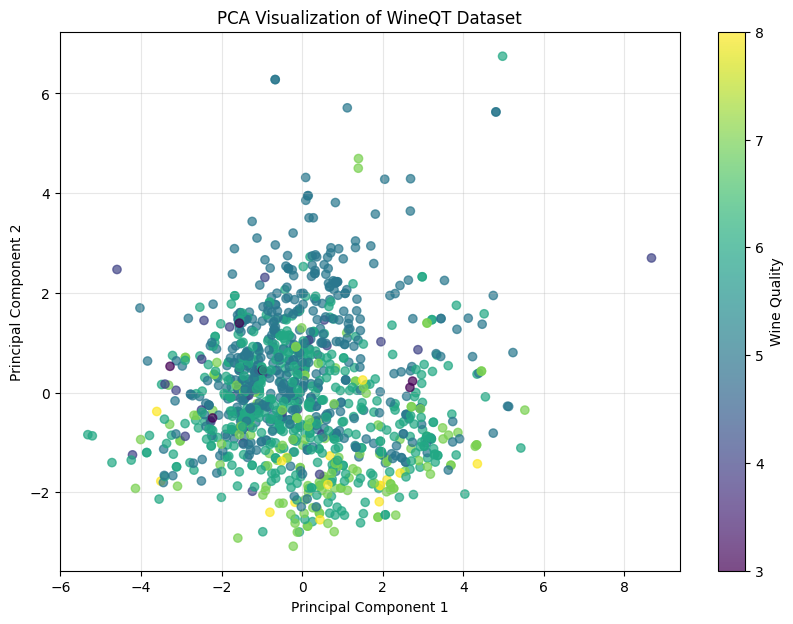

In [10]:
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    pca_df["Principal Component 1"],
    pca_df["Principal Component 2"],
    c=pca_df["quality"],
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of WineQT Dataset")

plt.colorbar(scatter, label="Wine Quality")
plt.grid(True, alpha=0.3)
plt.show()


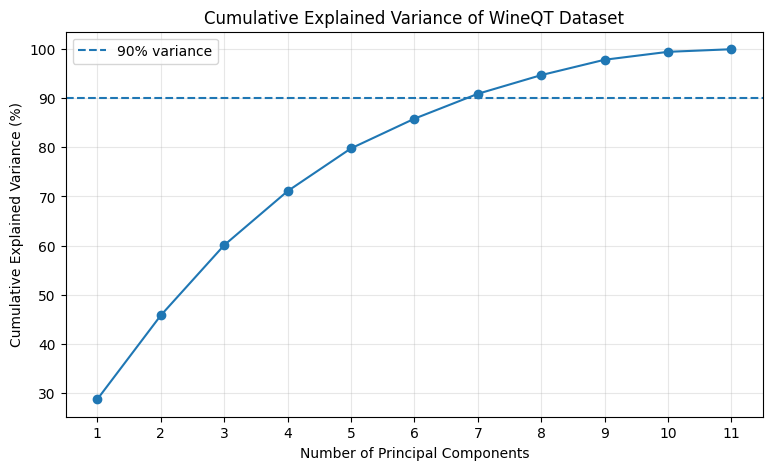

Components needed for at least 90% variance: 7


In [11]:
pca_full = PCA()
pca_full.fit(X_scaled)

cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
)

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker="o"
)

plt.axhline(y=90, linestyle="--", label="90% variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("Cumulative Explained Variance of WineQT Dataset")
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

components_90 = np.argmax(cumulative_variance >= 0.90) + 1

print("Components needed for at least 90% variance:",
      components_90)

In [12]:
print("========== PCA SUMMARY ==========")
print("Number of samples:", X.shape[0])
print("Original number of features:", X.shape[1])
print("Reduced number of features:", X_pca.shape[1])
print("PC1 variance:", round(explained_variance[0] * 100, 2), "%")
print("PC2 variance:", round(explained_variance[1] * 100, 2), "%")
print("Total variance retained:", round(total_variance * 100, 2), "%")
print("Components needed for 90% variance:", components_90)
print("=================================")


========== PCA SUMMARY ==========
Number of samples: 1143
Original number of features: 11
Reduced number of features: 2
PC1 variance: 28.69 %
PC2 variance: 17.08 %
Total variance retained: 45.77 %
Components needed for 90% variance: 7
